# TP - Construire et valider un MLP avec Dry Bean

Ce notebook reprend les étapes du TP fourni : analyse, séparation sans fuite, scaling, MLP, entraînement, courbes, prédictions, comparaisons, régularisation, EarlyStopping, validation finale et sauvegarde. Les passages du notebook de référence sont utilisés comme structure de travail ; les consignes qu'il contient ne remplacent pas cette demande.

## Préparation de l'environnement

In [3]:
%pip install -q ucimlrepo
%pip install seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier

SEED=42
keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')
print('TensorFlow:',tf.__version__)

Note: you may need to restart the kernel to use updated packages.
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.
TensorFlow: 2.21.0


## 1. Charger et analyser les données

In [12]:
# On récupère le jeu Dry Bean et sa cible.
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features.copy()
y_raw = dry_bean.data.targets.iloc[:, 0].astype(str).to_numpy()

feature_names = X.columns.tolist()

print('X:', X.shape, 'y:', y_raw.shape)

print('Types:')
print(X.dtypes.value_counts())

print('Valeurs manquantes:', int(X.isna().sum().sum()))
print('Doublons:', int(X.duplicated().sum()))

print('Effectifs:')
print(pd.Series(y_raw).value_counts().sort_index())

display(X.describe().T.round(2))

assert X.shape[0] == len(y_raw) and X.select_dtypes(exclude=np.number).shape[1] == 0
assert X.isna().sum().sum() == 0

print('Validation EDA: dimensions, types et valeurs manquantes OK.')

X: (13611, 16) y: (13611,)
Types:
float64    14
int64       2
Name: count, dtype: int64
Valeurs manquantes: 0
Doublons: 68
Effectifs:
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.28,29324.10,20420.00,36328.00,44652.00,61332.00,254616.00
Perimeter,13611.0,855.28,214.29,524.74,703.52,794.94,977.21,1985.37
MajorAxisLength,13611.0,320.14,85.69,183.60,253.30,296.88,376.50,738.86
MinorAxisLength,13611.0,202.27,44.97,122.51,175.85,192.43,217.03,460.20
AspectRatio,13611.0,1.58,0.25,1.02,1.43,1.55,1.71,2.43
Eccentricity,13611.0,0.75,0.09,0.22,0.72,0.76,0.81,0.91
ConvexArea,13611.0,53768.20,29774.92,20684.00,36714.50,45178.00,62294.00,263261.00
EquivDiameter,13611.0,253.06,59.18,161.24,215.07,238.44,279.45,569.37
Extent,13611.0,0.75,0.05,0.56,0.72,0.76,0.79,0.87
Solidity,13611.0,0.99,0.00,0.92,0.99,0.99,0.99,0.99


Validation EDA: dimensions, types et valeurs manquantes OK.


## 2. Séparer et préparer sans fuite
Les doublons sont retirés avant la séparation. Le scaler est ajusté uniquement sur le train ; le test reste inutilisé jusqu'à l'évaluation finale.

In [5]:
# On retire les doublons avant de séparer les données.
keep=~X.duplicated(keep='first')
X=X.loc[keep].reset_index(drop=True).astype('float32'); y_raw=y_raw[keep.to_numpy()]
# On transforme les noms de classes en nombres compris entre 0 et 6.
encoder=LabelEncoder(); y=encoder.fit_transform(y_raw).astype('int64')
# 20 % sont gardés pour le test, puis 25 % du reste pour la validation.
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,stratify=y_dev,random_state=SEED)
scaler=StandardScaler(); X_train_s=scaler.fit_transform(X_train).astype('float32')
# La validation et le test utilisent le scaler appris sur le train.
X_val_s=scaler.transform(X_val).astype('float32'); X_test_s=scaler.transform(X_test).astype('float32')
n_features,n_classes=X_train_s.shape[1],len(encoder.classes_)
print('Train/val/test:',X_train.shape,X_val.shape,X_test.shape)
print('Classes:',list(encoder.classes_))
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index)
assert np.abs(X_train_s.mean(axis=0)).max()<1e-5
print('Validation séparation/scaler: aucune fuite détectée.')

Train/val/test: (8125, 16) (2709, 16) (2709, 16)
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Validation séparation/scaler: aucune fuite détectée.


## 3. Construire, compiler et entraîner le MLP

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

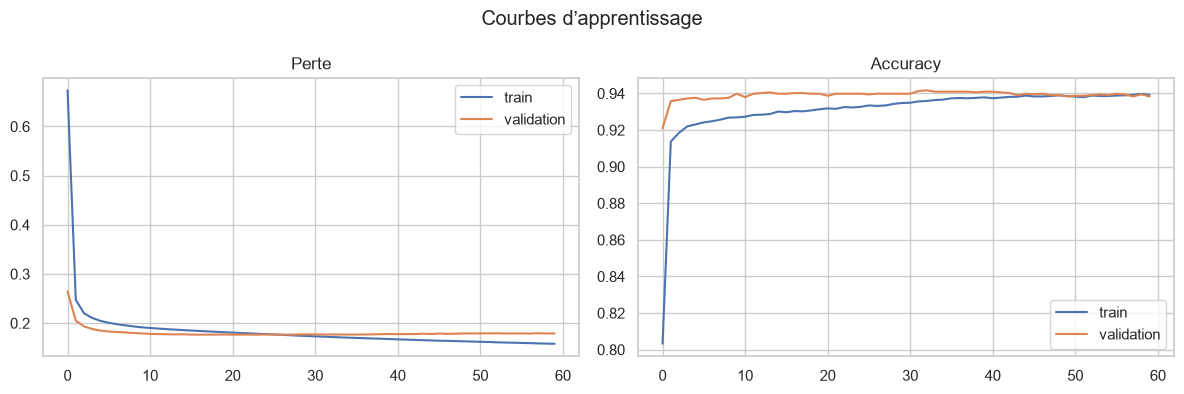

Meilleure époque: 24


In [6]:
# Le MLP apprend des représentations puis prédit une classe de haricot.
def create_model(hidden=(64,32),activation='relu',rate=.001,dropout=0,penalty=None):
    # Chaque couche cachée apprend des combinaisons de variables.
    net=keras.Sequential([keras.Input(shape=(n_features,))])
    for units in hidden:
        net.add(layers.Dense(units,activation=activation,kernel_regularizer=penalty))
        if dropout: net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes,activation='softmax'))
    # Softmax donne une probabilité pour chaque classe.
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=rate),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return net
model=create_model(); model.summary()
# fit apprend les poids à partir des exemples d'entraînement.
history=model.fit(X_train_s,y_train,validation_data=(X_val_s,y_val),epochs=60,batch_size=32,verbose=0)
def plot_history(hist,title='Courbes d’apprentissage'):
    # Les courbes permettent de repérer un surapprentissage éventuel.
    h=hist.history; fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(h['loss'],label='train'); ax[0].plot(h['val_loss'],label='validation'); ax[0].set_title('Perte'); ax[0].legend()
    ax[1].plot(h['accuracy'],label='train'); ax[1].plot(h['val_accuracy'],label='validation'); ax[1].set_title('Accuracy'); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()
plot_history(history)
print('Meilleure époque:',np.argmin(history.history['val_loss'])+1)

## 4. Prédire et valider
On affiche accuracy, balanced accuracy, F1 macro, rapport par classe et matrice de confusion.

Validation {'accuracy': 0.9384, 'balanced_accuracy': 0.9468, 'f1_macro': 0.9489}
              precision    recall  f1-score   support

    BARBUNYA       0.97      0.93      0.95       264
      BOMBAY       1.00      1.00      1.00       105
        CALI       0.93      0.98      0.95       326
    DERMASON       0.90      0.96      0.93       710
       HOROZ       0.97      0.94      0.95       372
       SEKER       0.97      0.97      0.97       405
        SIRA       0.93      0.85      0.89       527

    accuracy                           0.94      2709
   macro avg       0.95      0.95      0.95      2709
weighted avg       0.94      0.94      0.94      2709



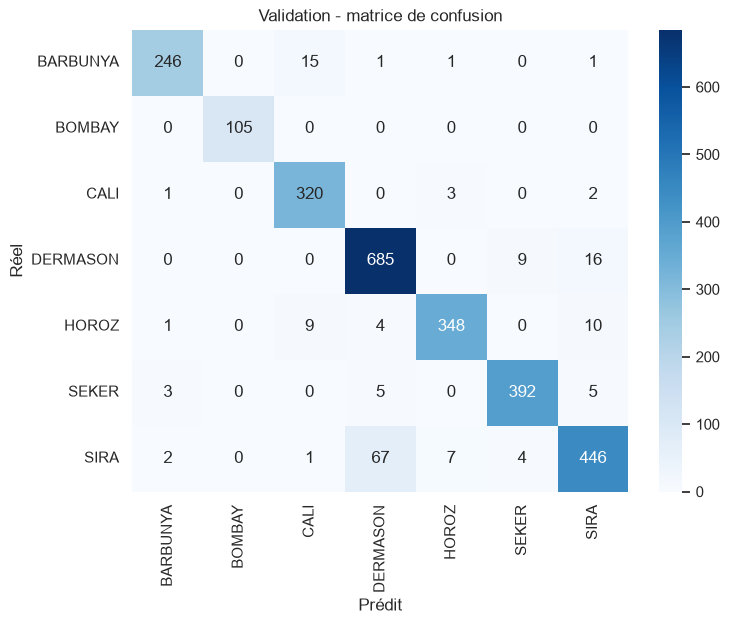

Validation prédictions: probabilités valides.


In [7]:
# On transforme les probabilités en classes et on calcule plusieurs métriques.
def evaluate_predictions(name,net,Xe,ye,show=True):
    # predict renvoie les probabilités produites par le réseau.
    proba=net.predict(Xe,verbose=0); pred=proba.argmax(axis=1)
    scores={'accuracy':accuracy_score(ye,pred),'balanced_accuracy':balanced_accuracy_score(ye,pred),'f1_macro':f1_score(ye,pred,average='macro')}
    # Le F1 macro donne le même poids à chaque classe.
    print(name,{k:round(v,4) for k,v in scores.items()})
    if show:
        print(classification_report(ye,pred,target_names=encoder.classes_,zero_division=0))
        plt.figure(figsize=(8,6)); sns.heatmap(confusion_matrix(ye,pred),annot=True,fmt='d',cmap='Blues',xticklabels=encoder.classes_,yticklabels=encoder.classes_)
        plt.xlabel('Prédit'); plt.ylabel('Réel'); plt.title(name+' - matrice de confusion'); plt.show()
    return scores,pred,proba
val_scores,val_pred,val_proba=evaluate_predictions('Validation',model,X_val_s,y_val)
assert val_proba.shape==(len(y_val),n_classes) and np.allclose(val_proba.sum(axis=1),1,atol=1e-5)
print('Validation prédictions: probabilités valides.')

## 5. Comparer des architectures et de la régularisation
Chaque essai utilise un modèle neuf. La validation sert au choix ; le test n'est pas consulté.

référence {'accuracy': 0.9409, 'balanced_accuracy': 0.9491, 'f1_macro': 0.9513}
petit réseau {'accuracy': 0.9413, 'balanced_accuracy': 0.9498, 'f1_macro': 0.9506}
tanh {'accuracy': 0.942, 'balanced_accuracy': 0.9498, 'f1_macro': 0.9516}
dropout + L2 {'accuracy': 0.9398, 'balanced_accuracy': 0.9485, 'f1_macro': 0.9499}


,accuracy,balanced_accuracy,f1_macro
tanh,0.9420,0.9498,0.9516
référence,0.9409,0.9491,0.9513
petit réseau,0.9413,0.9498,0.9506
dropout + L2,0.9398,0.9485,0.9499


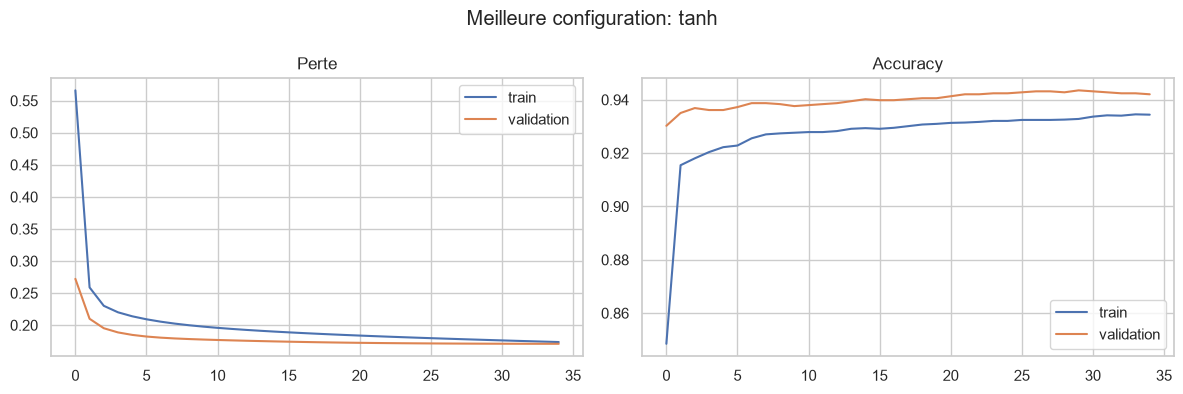

In [8]:
# Chaque réglage est testé sur la validation, sans utiliser le test.
def run_experiment(name,**kwargs):
    keras.utils.set_random_seed(SEED); net=create_model(**kwargs)
    hist=net.fit(X_train_s,y_train,validation_data=(X_val_s,y_val),epochs=35,batch_size=32,verbose=0)
    scores,_,_=evaluate_predictions(name,net,X_val_s,y_val,show=False); return net,hist,scores
configs={'référence':{},'petit réseau':{'hidden':(32,)},'tanh':{'hidden':(64,32),'activation':'tanh'},'dropout + L2':{'hidden':(128,64),'dropout':.25,'penalty':keras.regularizers.l2(1e-4)}}
runs={name:run_experiment(name,**cfg) for name,cfg in configs.items()}
# On choisit la configuration ayant le meilleur F1 macro de validation.
comparison=pd.DataFrame({n:s for n,(_,_,s) in runs.items()}).T.sort_values('f1_macro',ascending=False)
display(comparison.round(4))
best_name=comparison.index[0]; best_model,best_history,_=runs[best_name]
plot_history(best_history,'Meilleure configuration: '+best_name)

## 6. EarlyStopping et évaluation finale sur le test

Époques exécutées: 40


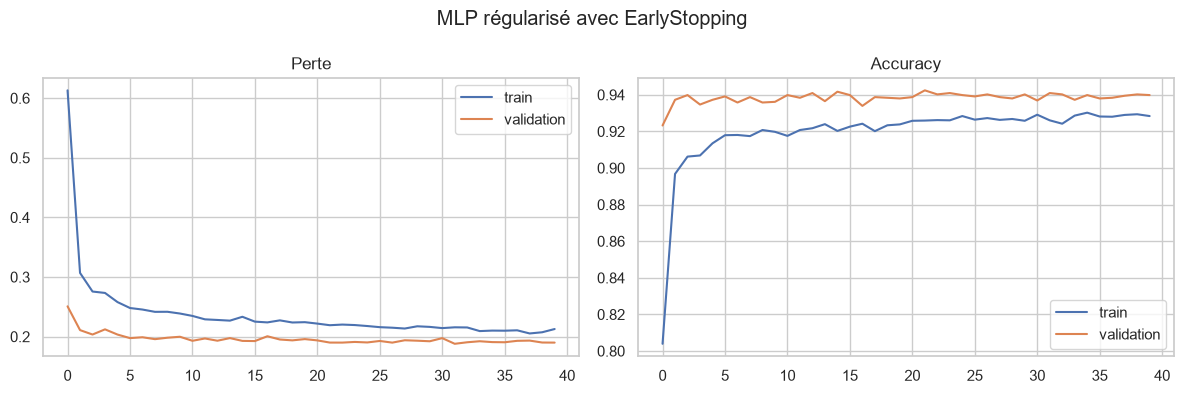

Test - modèle retenu {'accuracy': 0.9199, 'balanced_accuracy': 0.9295, 'f1_macro': 0.9305}
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.90      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.95      0.92       326
    DERMASON       0.89      0.94      0.92       709
       HOROZ       0.97      0.92      0.95       372
       SEKER       0.94      0.96      0.95       406
        SIRA       0.91      0.83      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



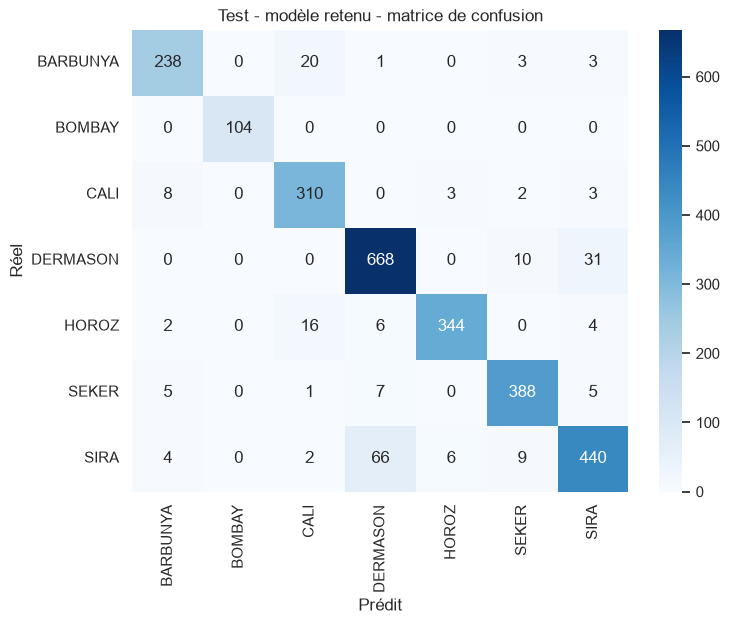

Baseline majoritaire: {'accuracy': 0.2617, 'balanced_accuracy': 0.1429, 'f1_macro': 0.0593}
Validation finale: test évalué après le choix du modèle.


In [9]:
# EarlyStopping arrête l'apprentissage quand la validation ne progresse plus.
early_stop=keras.callbacks.EarlyStopping(monitor='val_loss',patience=8,restore_best_weights=True)
keras.utils.set_random_seed(SEED)
early_model=create_model(hidden=(128,64),dropout=.25,penalty=keras.regularizers.l2(1e-4))
early_history=early_model.fit(X_train_s,y_train,validation_data=(X_val_s,y_val),epochs=150,batch_size=32,callbacks=[early_stop],verbose=0)
print('Époques exécutées:',len(early_history.history['loss']))
plot_history(early_history,'MLP régularisé avec EarlyStopping')
test_scores,test_pred,test_proba=evaluate_predictions('Test - modèle retenu',early_model,X_test_s,y_test)
# La baseline prédit toujours la classe la plus fréquente.
baseline=DummyClassifier(strategy='most_frequent').fit(X_train_s,y_train); base_pred=baseline.predict(X_test_s)
print('Baseline majoritaire:',{'accuracy':round(accuracy_score(y_test,base_pred),4),'balanced_accuracy':round(balanced_accuracy_score(y_test,base_pred),4),'f1_macro':round(f1_score(y_test,base_pred,average='macro'),4)})
assert test_proba.shape[0]==len(y_test)
print('Validation finale: test évalué après le choix du modèle.')

## 7. Sauvegarder et recharger
Le modèle ne contient pas le scaler ni le mapping des classes : ils sont sauvegardés séparément.

In [10]:
# Le modèle et le prétraitement sont sauvegardés pour une future prédiction.
early_model.save('modele_dry_bean.keras')
np.savez('dry_bean_preprocessing.npz',mean=scaler.mean_,scale=scaler.scale_,classes=encoder.classes_,features=np.array(feature_names))
loaded_model=keras.models.load_model('modele_dry_bean.keras')
# Les prédictions doivent rester identiques après le rechargement.
before=early_model.predict(X_test_s[:10],verbose=0); after=loaded_model.predict(X_test_s[:10],verbose=0)
print('Écart maximal avant/après rechargement:',float(np.max(np.abs(before-after))))
assert np.allclose(before,after,atol=1e-6)
print('Validation sauvegarde/rechargement: OK.')

Écart maximal avant/après rechargement: 0.0
Validation sauvegarde/rechargement: OK.


## Conclusion
Le protocole est leakage-safe, visualise les données et l'apprentissage, compare plusieurs choix sur validation, mesure les classes minoritaires avec le F1 macro et réserve le test à une évaluation finale. Conserver ensemble `modele_dry_bean.keras`, `dry_bean_preprocessing.npz` et l'ordre des variables.